In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Dados_Formasdeonda.xlsx to Dados_Formasdeonda (3).xlsx


In [1]:
import pandas as pd
import io
df = pd.read_excel(io.BytesIO(uploaded['Dados_Formasdeonda.xlsx']))
df

NameError: ignored

In [ ]:
tempo = 1e3 * df['Tempo']
corrente = df['VA LTSPA2-138kV']
deriv_corrente = np.gradient(corrente, tempo)

In [ ]:
import numpy as np
zero_crossings = np.where(np.diff(np.sign(corrente)))[0]

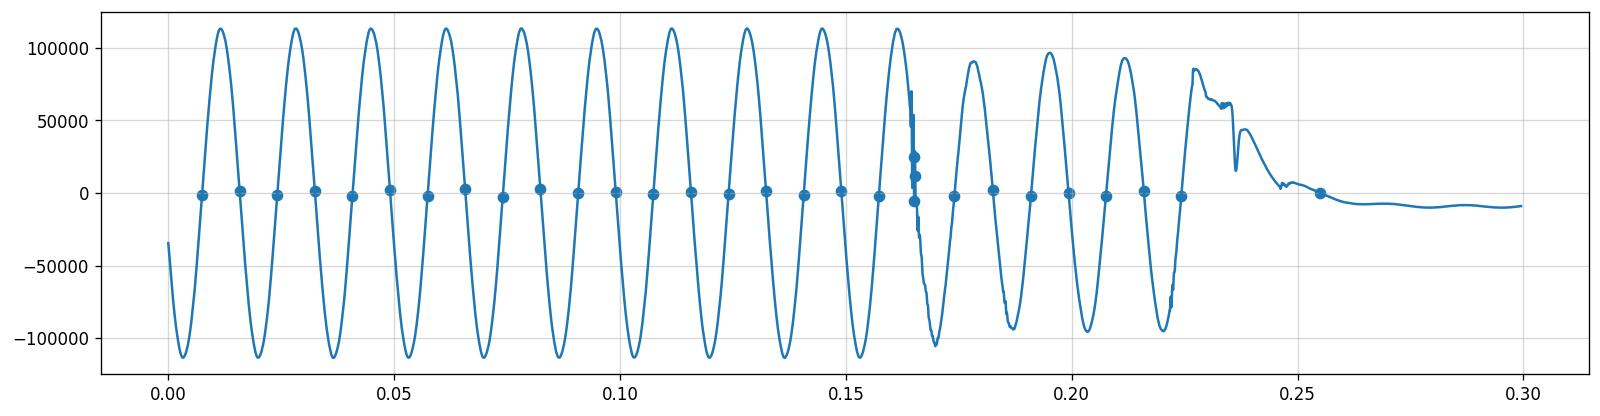

In [ ]:
import matplotlib.pyplot as plt
fig1 = plt.figure(figsize=(16,4), dpi=120)
ax1 = plt.axes();
ax1.plot(tempo,corrente)
ax1.scatter(tempo[zero_crossings],corrente[zero_crossings])
#ax1.plot(tempo,deriv_corrente/1e3)
ax1.grid(alpha=0.5)

In [ ]:
#Inicio = tempo[zero_crossings[0]]
#Periodo = tempo[zero_crossings[2]] - tempo[zero_crossings[0]]
#PontosPorCiclo = zero_crossings[2] - zero_crossings[0]
#DeltaTempo = tempo[1] - tempo[0]
#NumeroDeCiclos = 14 # do 0 ao 14

In [ ]:
npts = len(tempo);
dtempo = tempo[1] - tempo[0]
dfreq = 1 / tempo[npts-1]
h = np.arange(0, npts/2, 1)
FREQ = dfreq * h
dfreq

3.339399909836468

In [ ]:
Ia = np.fft.fft(corrente)
mod_Ia = ( np.abs(Ia) )
mod_Ia = 2/npts * mod_Ia
arg_Ia = np.angle(Ia)

2304

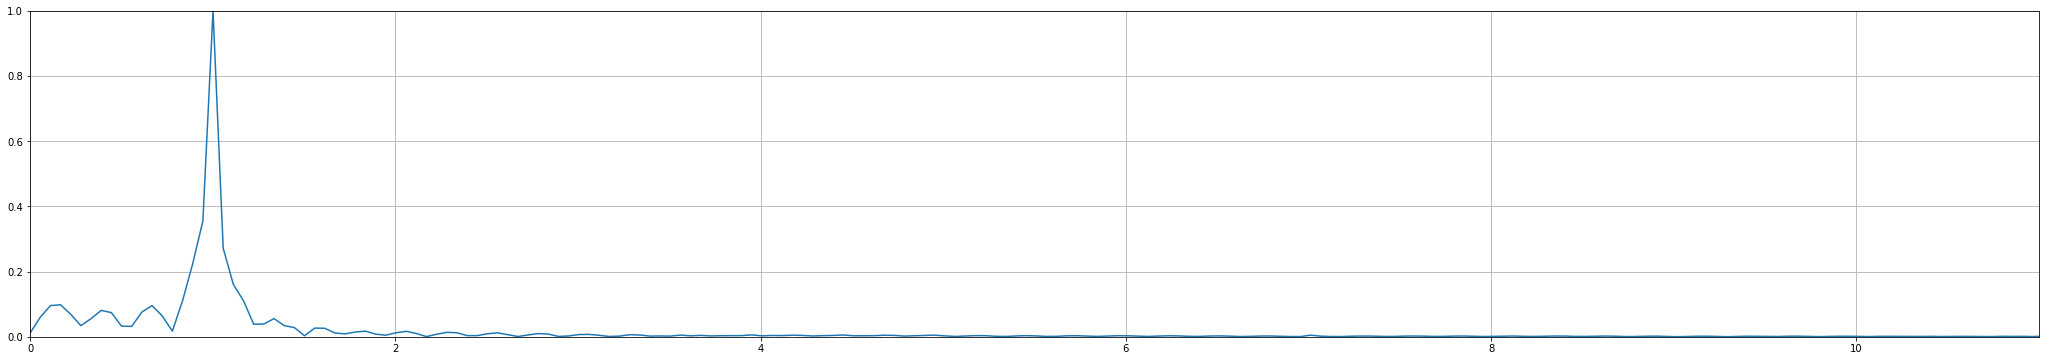

In [ ]:
fim = int(npts/2)
plt.figure(figsize=(36,6))
plt.plot(FREQ/60, mod_Ia[0:fim]/np.max(mod_Ia))
plt.xlim(0,11)
plt.ylim(0,1)
plt.grid()

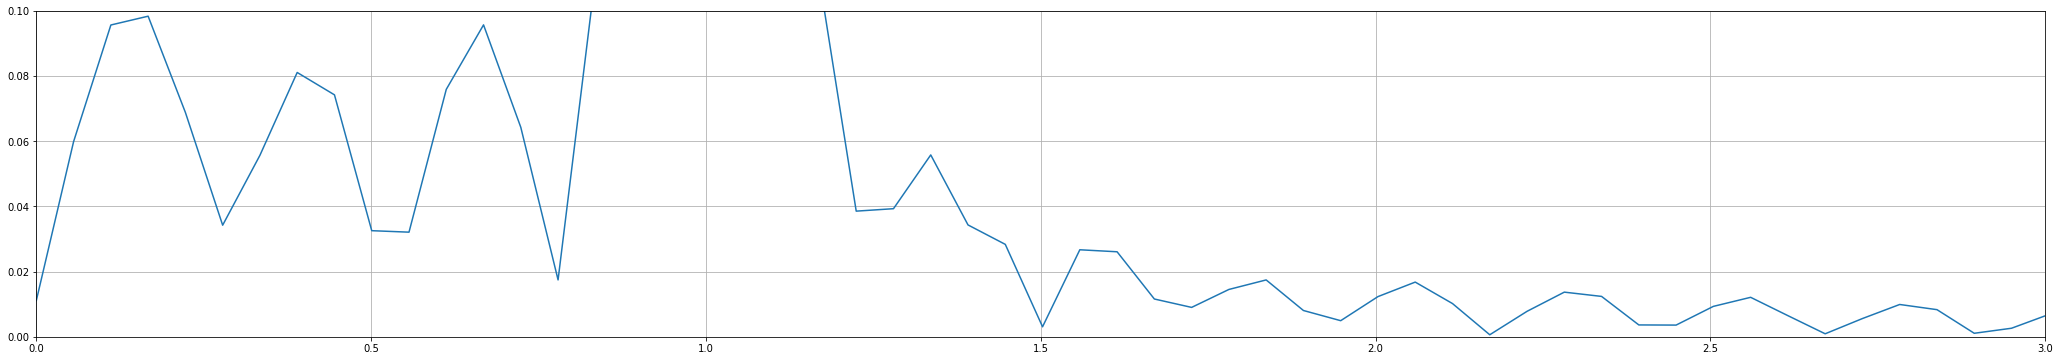

In [ ]:
fim = int(npts/2)
plt.figure(figsize=(36,6))
plt.plot(FREQ/60, mod_Ia[0:fim]/np.max(mod_Ia))
plt.xlim(0,3)
plt.ylim(0,0.1)
plt.grid()